[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ArtIC-TITECH/b3-proj-2026/blob/main/docs/class_02.ipynb)

# 本日の内容

## 目次
1. 過学習について
1. パラメータの数え方
1. モデルの軽量化
  - 量子化
  - 枝刈り
  - Model Folding
4. テーマの割り当て

## 1. 過学習について

### 1-0.ライブラリのインポート

In [44]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.init as init
import numpy as np
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader, Subset

### 1-1.データセットの作成

In [45]:
# 普通のtransform (変更可能)
transform_normal = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# テストデータには普通のtransformを使ってください
transform_for_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform_normal)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform_for_test)

# ===== 追加：学習データをSubsetにする (過学習を引き起こすため) =====
subset_ratio = 0.008

generator = torch.Generator().manual_seed(42)
indices = torch.randperm(len(train_dataset), generator=generator)[:int(subset_ratio * len(train_dataset))]
    
overfitting_dataset = Subset(train_dataset, indices.tolist())
# =======================================

train_loader = DataLoader(
    overfitting_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4096,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

### 1-2.モデルの作成

In [46]:
class SimpleModel(nn.Module):
    def __init__(self): # モデルのセットアップ
        super(SimpleModel, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 128)
        self.fc4 = nn.Linear(128, 10)

    def forward(self, x): # モデルが行う処理
        x = x.view(-1, 28 * 28)  # 28x28の画像を１次元に変換
        x = self.fc1(x) # ベクトルサイズを28x28から128へ
        x = nn.ReLU()(x) # 活性化関数
        x = self.fc2(x) # ベクトルサイズを128から128へ
        x = nn.ReLU()(x) # 活性化関数
        x = self.fc3(x) # ベクトルサイズを128から128へ
        x = self.fc4(x) # ベクトルサイズを128から10へ
        return x

# モデルのインスタンスを作成
model = SimpleModel().cuda()

### 1-3. 損失関数, 最適化関数の定義

In [47]:
criterion = nn.CrossEntropyLoss()
# 変更可能
optimizer = optim.SGD(model.parameters(), lr=0.05)

### 1-4. モデルの学習

モデルを200エポック訓練します。  
各エポックでの訓練損失, テスト損失, 訓練精度, テスト精度を取得します。

In [48]:
# エポック数
epochs = 200

# 訓練とテストの損失・精度を記録するリスト
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(epochs):
    # 訓練フェーズ
    model.train()

    loss_sum = torch.zeros((), device="cuda")
    correct_train = torch.zeros((), device="cuda")
    total_train = 0

    for images, labels in train_loader:
        images = images.cuda(non_blocking=True)
        labels = labels.cuda(non_blocking=True)

        # 勾配の初期化
        optimizer.zero_grad(set_to_none=True)

        # モデルの予測
        outputs = model(images)

        # 損失の計算
        loss = criterion(outputs, labels)

        # バックプロパゲーション
        loss.backward()

        # オプティマイザの更新
        optimizer.step()

        # 損失・精度の集計（GPU上）
        batch_size = labels.size(0)
        loss_sum += loss.detach() * batch_size
        correct_train += (outputs.detach().argmax(1) == labels).sum()
        total_train += batch_size

    # 訓練損失と訓練精度
    train_loss = loss_sum.item() / total_train
    train_accuracy = 100 * correct_train.item() / total_train

    # テストフェーズ
    model.eval()

    loss_sum_test = torch.zeros((), device="cuda")
    correct_test = torch.zeros((), device="cuda")
    total_test = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.cuda(non_blocking=True)
            labels = labels.cuda(non_blocking=True)

            # モデルの予測
            outputs = model(images)

            # 損失の計算
            loss = criterion(outputs, labels)

            # 損失・精度の集計（GPU上）
            batch_size = labels.size(0)
            loss_sum_test += loss * batch_size
            correct_test += (outputs.argmax(1) == labels).sum()
            total_test += batch_size

    # テスト損失とテスト精度
    test_loss = loss_sum_test.item() / total_test
    test_accuracy = 100 * correct_test.item() / total_test

    # 訓練とテストの損失・精度をリストに保存
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    # 損失と精度を表示
    print(f'Epoch [{epoch+1}/{epochs}]')
    print(f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%')
    print(f'Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%')

Epoch [1/200]
Train Loss: 2.2991, Train Accuracy: 10.42%
Test Loss: 2.2917, Test Accuracy: 12.81%
Epoch [2/200]
Train Loss: 2.2840, Train Accuracy: 14.58%
Test Loss: 2.2792, Test Accuracy: 20.87%
Epoch [3/200]
Train Loss: 2.2698, Train Accuracy: 26.88%
Test Loss: 2.2657, Test Accuracy: 27.02%
Epoch [4/200]
Train Loss: 2.2538, Train Accuracy: 30.00%
Test Loss: 2.2493, Test Accuracy: 32.78%
Epoch [5/200]
Train Loss: 2.2354, Train Accuracy: 36.46%
Test Loss: 2.2308, Test Accuracy: 33.24%
Epoch [6/200]
Train Loss: 2.2125, Train Accuracy: 36.25%
Test Loss: 2.2074, Test Accuracy: 35.64%
Epoch [7/200]
Train Loss: 2.1860, Train Accuracy: 39.38%
Test Loss: 2.1792, Test Accuracy: 36.68%
Epoch [8/200]
Train Loss: 2.1524, Train Accuracy: 38.33%
Test Loss: 2.1457, Test Accuracy: 39.01%
Epoch [9/200]
Train Loss: 2.1136, Train Accuracy: 40.42%
Test Loss: 2.1020, Test Accuracy: 40.05%
Epoch [10/200]
Train Loss: 2.0633, Train Accuracy: 41.88%
Test Loss: 2.0501, Test Accuracy: 44.16%
Epoch [11/200]
Trai

### 1-5. 過学習について

以下のセルは各エポックでの訓練損失, テスト損失, 訓練精度, テスト精度をプロットするものです。

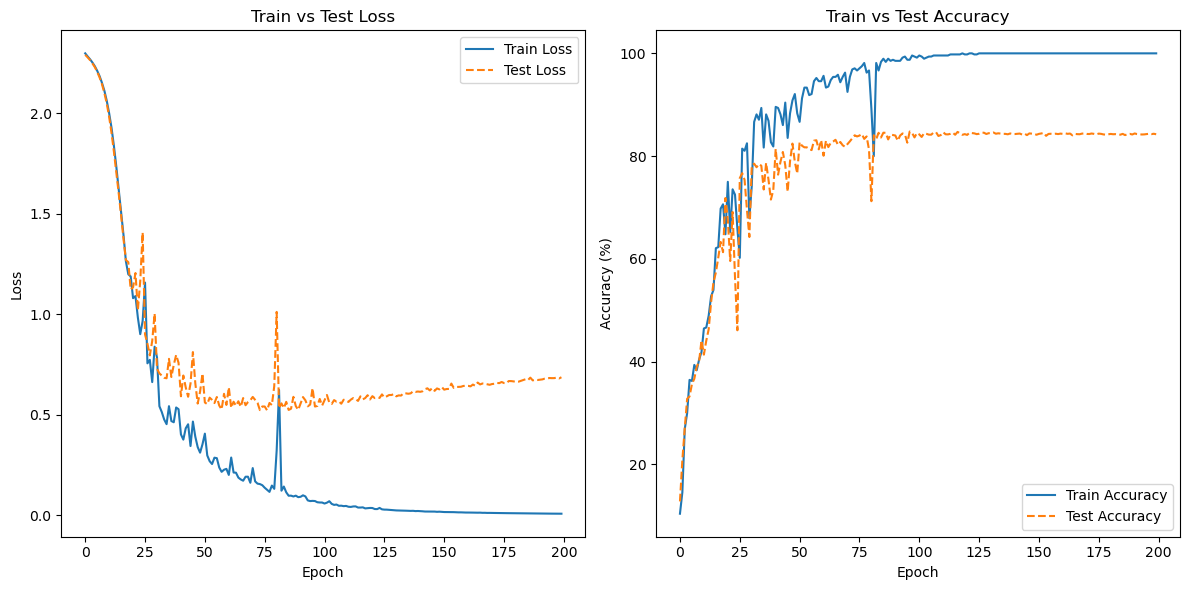

In [49]:
# 訓練とテストの損失をプロット
plt.figure(figsize=(12, 6))

# 損失のプロット
plt.subplot(1, 2, 1)
plt.plot(range(epochs), train_losses, label='Train Loss')
plt.plot(range(epochs), test_losses, label='Test Loss', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train vs Test Loss')
plt.legend()

# 精度のプロット
plt.subplot(1, 2, 2)
plt.plot(range(epochs), train_accuracies, label='Train Accuracy')
plt.plot(range(epochs), test_accuracies, label='Test Accuracy', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Train vs Test Accuracy')
plt.legend()

# プロットを表示
plt.tight_layout()
plt.show()

左がLossで右が精度です。  
訓練(青)とテスト(オレンジ)を比較すると、訓練(青)はLossが下がり続ける一方、テスト(オレンジ)は途中からLossが上がっていることがわかります。  
この差は過学習によるものです。
過学習はモデルが訓練データに適合しすぎる現象で、学習時の設定を工夫しないと起きてしまうため、注意が必要です (今回は訓練データ数を減らす・Epoch数を大きくすることで過学習を発生させました)。

## 2. パラメータの数え方

### 2-0.ライブラリのインポート

In [50]:
import torch
import torch.nn as nn
import torch.nn.init as init

### 2-1.モデルの定義

前回、線形関数の近似で使った$y=wx+b$を使います。  
この関数で学習可能なパラメータは$w$と$b$の2つです。

In [51]:
# モデルの定義
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super(LinearRegressionModel, self).__init__()
        self.linear = nn.Linear(1, 1)  # 入力1、出力1の線形層
        init.constant_(self.linear.weight, 0)  # 重みwをすべて0に初期化
        init.constant_(self.linear.bias, 0)    # バイアスbをすべて0に初期化

    def forward(self, x):
        return self.linear(x)

# モデルのインスタンスを作成
model = LinearRegressionModel().cuda()

### 2-2. パラメータの数え方

学習可能なパラメータ$w$と$b$はmodel.parameters()によってアクセスできます。

In [52]:
for p in model.parameters():
  print(p)

Parameter containing:
tensor([[0.]], device='cuda:0', requires_grad=True)
Parameter containing:
tensor([0.], device='cuda:0', requires_grad=True)


パラメータ数は以下のようにカウントできます。  
numelは"number of elements"(要素数)の略です。

In [53]:
num_params = sum(p.numel() for p in model.parameters())
num_params

2

### 2-3. nn.Linearのパラメータ数

最後にnn.Linear(入力サイズ, 出力サイズ)のパラメータ数について説明します。  
nn.Linearは(出力サイズ$\times$入力サイズ)の重み行列$\mathbf{W}$と(出力サイズ)のバイアスベクトル$b$を生成します。   
したがって、パラメータ数は  
```
出力サイズ×入力サイズ+出力サイズ  
```
で計算できます。

In [54]:
# 入力チャンネル数と出力チャンネル数を指定して線形層を作成
input_channels = 5
output_channels = 3
linear_layer = nn.Linear(input_channels, output_channels)

# パラメータ数を計算
num_params = sum(p.numel() for p in linear_layer.parameters())

print(f"nn.Linear({input_channels}, {output_channels}) のパラメータ数: {num_params}")

nn.Linear(5, 3) のパラメータ数: 18


## 3. モデルの軽量化

ChatGPTに代表される大規模言語モデルは大量のパラメータを持っています。  
例えば、Llama 7Bは約70億のパラメータを持ち、32ビット浮動小数点数で保存すると、約28GBのメモリが必要です。  
今回は、モデルの軽量化技術として
- パラメータを低ビットで表現する量子化
- 一部パラメータを0にする枝刈り
- モデルの重みを再利用する Model Folding

について紹介します。

### 3-1. 量子化について

ライブラリのimport

In [55]:
import torch

今回は4つの要素を持つテンソルを量子化します。

In [56]:
# 4つの要素を持つ乱数で初期化したテンソルを作成
original_tensor = torch.rand(4)  # 0から1の範囲の一様分布で初期化
print("量子化するテンソル:", original_tensor)

量子化するテンソル: tensor([0.9920, 0.2319, 0.0082, 0.9744])


今回はmin-maxスケーリングと呼ばれる量子化について説明します。  
min-maxスケーリングは最小値と最大値を基に、データを指定した範囲にスケーリングします。  
コードの例は8bit量子化(0~255)を行います。

<img src="https://raw.githubusercontent.com/ArtIC-TITECH/b3-proj-2024/refs/heads/main/resources/class_01/quant_asym.png" width="50%">

min-maxスケーリングのアルゴリズム
1. 最小値を0にするためにテンソルをminでひく。
1. 0~255の範囲にするためにテンソルに255/(max-min)を乗算する。
1. 整数化する。

In [57]:
# 最大値と最小値の取得
tensor_max = original_tensor.max()
tensor_min = original_tensor.min()

# 量子化
# テンソルをminでひく
quantized_tensor = original_tensor - tensor_min
# テンソルに255/(max-min)を乗算する
quantized_tensor = quantized_tensor * 255 / (tensor_max-tensor_min)
# 整数化する
quantized_tensor = quantized_tensor.round().clamp(0, 255).int()
print("量子化されたテンソル:", quantized_tensor)

量子化されたテンソル: tensor([255,  58,   0, 250], dtype=torch.int32)


int32とありますが0から255の範囲です。  
量子化と反対の操作をすることでオリジナルのテンソルに近いテンソルが得られます。

In [58]:
# 復元
dequantized_tensor = quantized_tensor.float() * (tensor_max-tensor_min) / 255
dequantized_tensor = dequantized_tensor + tensor_min
print("オリジナルのテンソル:", original_tensor)
print("復元されたテンソル:", dequantized_tensor)

オリジナルのテンソル: tensor([0.9920, 0.2319, 0.0082, 0.9744])
復元されたテンソル: tensor([0.9920, 0.2320, 0.0082, 0.9727])



### ※補足：ベクトル量子化

ベクトル量子化は、１つの要素を整数値に丸めるのではなく、ベクトル全体を代表ベクトルで置き換えてインデックスで表現します。
代表ベクトルの求め方は、k-meansクラスタリングアルゴリズムで求めることが一般的です。

<img src="https://raw.githubusercontent.com/ArtIC-TITECH/b3-proj-2025/refs/heads/main/resources/class_02/k-means.png" width="50%">

In [59]:
import torch
from sklearn.cluster import KMeans

# 乱数で初期化されたテンソル
tensor = torch.randn(8, 8)
print("オリジナルのテンソル:\n", tensor)

# --- K-means でベクトル量子化 ---
# 各行をクラスタリング対象とする
X = tensor.numpy()

# クラスタ数を指定 (例: 3 クラスタ)
k = 3
kmeans = KMeans(n_clusters=k, random_state=0, n_init="auto").fit(X)

# 各行を対応するクラスタ中心に置き換え
X_quantized = kmeans.cluster_centers_[kmeans.labels_]

tensor_vq = torch.tensor(X_quantized, dtype=torch.float32)

print("\nK-means (k={}) 量子化後のテンソル:\n".format(k), tensor_vq)

# --- 誤差（Frobeniusノルム）---
error = torch.norm(tensor - tensor_vq)
print("\n量子化誤差 (Frobenius norm):", error.item())


オリジナルのテンソル:
 tensor([[ 1.8762e-01,  2.1863e-01, -8.8083e-01,  1.2761e+00, -1.3986e-01,
          5.7646e-01, -8.3579e-02,  3.1395e+00],
        [ 1.6707e+00, -1.9999e+00,  6.9664e-01, -5.6982e-01,  1.8901e-02,
          2.4544e+00,  1.4177e+00, -2.3295e-01],
        [ 2.3111e-01,  2.7709e-01, -2.5384e-01, -1.1282e-01, -3.5189e-01,
          1.7031e+00, -2.2125e-01,  9.9405e-02],
        [-4.7774e-01,  5.8349e-01,  2.6801e+00,  1.1642e-02,  2.9338e-01,
         -8.1257e-01, -5.7510e-01,  6.1710e-01],
        [ 1.3616e+00, -1.7290e-01, -1.5876e+00, -6.3546e-01, -4.8144e-01,
         -1.3457e+00, -5.5379e-01,  3.6490e-01],
        [ 1.0094e+00, -2.5083e+00, -1.9063e-03,  4.9312e-01, -6.5565e-01,
          2.3250e-01,  1.5608e+00, -6.9353e-01],
        [-5.2532e-01, -1.2119e+00,  1.1922e-01, -1.3771e+00,  3.5712e-01,
          8.4237e-01, -7.4022e-01, -2.3414e-01],
        [-8.8339e-02,  3.1265e-01, -3.7554e-01, -9.8908e-01,  1.1408e+00,
         -2.4427e-01, -5.1378e-01,  6.6430e-01]])

K

### 3-2. 枝刈りについて

枝刈りは計算への影響が小さい要素を0にする処理です。  
今回は8つの要素を持つテンソルのうち、絶対値が小さい要素を0にする処理を実装します。

<img src="https://raw.githubusercontent.com/ArtIC-TITECH/b3-proj-2024/refs/heads/main/resources/class_01/pruning.svg" width="50%">

In [60]:
# 乱数で初期化されたテンソルを作成
tensor = torch.randn(8)
print("オリジナルのテンソル:", tensor)

# プルーニングする個数
num_prune = 2

# num_prune番目に小さい絶対値をスレッショルドに
threshold = torch.topk(tensor.abs(), num_prune, largest=False).values[-1]

# 絶対値が小さい要素をプルーニング
pruned_tensor = tensor.clone()
pruned_tensor[torch.abs(pruned_tensor) <= threshold] = 0

print("プルーニングされたテンソル:", pruned_tensor)

オリジナルのテンソル: tensor([ 0.2865, -0.0096, -2.0287,  0.6312, -0.3033, -1.2445, -0.7165, -0.4605])
プルーニングされたテンソル: tensor([ 0.0000,  0.0000, -2.0287,  0.6312, -0.3033, -1.2445, -0.7165, -0.4605])


### 3-3. Model Folding について
Model Foldingは、多層ニューラルネットワークの複数の層を、重みを共有する少数の層にまとめる手法です。
元のモデルより層数を減らし、同じ層を繰り返し適用することで、計算の深さを維持しながら必要な重みの数を減らします。
元のモデルより独立した層の数が少なくなるため、パラメータ数を削減でき、圧縮になります。

<img src="https://raw.githubusercontent.com/ArtIC-TITECH/b3-proj-2026/refs/heads/main/resources/class_02/folding.svg" width="50%">

#### 3-3-1.モデルの定義

1-2 で作成したモデルは、4層構造でした。
今回は、中央の2層部分について、単層を2回繰り返したモデルを評価します。

In [61]:
class FoldedSimpleModel(nn.Module):
    def __init__(self): # モデルのセットアップ
        super(FoldedSimpleModel, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x): # モデルが行う処理
        x = x.view(-1, 28 * 28)  # 28x28の画像を１次元に変換
        x = self.fc1(x) # ベクトルサイズを28x28から128へ
        x = nn.ReLU()(x) # 活性化関数
        for _ in range(2):  # 2層のReLUを適用
            x = self.fc2(x) # ベクトルサイズを128から128へ
            x = nn.ReLU()(x) # 活性化関数
        x = self.fc3(x) # ベクトルサイズを128から128へ
        return x

# モデルのインスタンスを作成
original_model = SimpleModel().cuda()
folded_model   = FoldedSimpleModel().cuda()

#### 3-3-2. 損失関数, 最適化関数, データの定義

In [62]:
orig_criterion   = nn.CrossEntropyLoss()
folded_criterion = nn.CrossEntropyLoss()

# 変更可能
orig_optimizer   = optim.SGD(original_model.parameters(), lr=0.05)
folded_optimizer = optim.SGD(folded_model.parameters(), lr=0.05)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4096,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

#### 3-3-3. モデルの学習

両モデルを15エポック分訓練します。  
各エポックでの訓練損失, テスト損失, 訓練精度, テスト精度を取得します。

In [63]:
epochs = 15

orig_train_losses, folded_train_losses = [], []
orig_test_losses, folded_test_losses = [], []
orig_train_accuracies, folded_train_accuracies = [], []
orig_test_accuracies, folded_test_accuracies = [], []

for epoch in range(epochs):
    # 訓練フェーズ
    original_model.train()
    folded_model.train()

    orig_loss_sum = torch.zeros((), device="cuda")
    folded_loss_sum = torch.zeros((), device="cuda")
    orig_correct_train = torch.zeros((), device="cuda")
    folded_correct_train = torch.zeros((), device="cuda")
    total_train = 0

    for images, labels in train_loader:
        images = images.cuda(non_blocking=True)
        labels = labels.cuda(non_blocking=True)

        # 勾配の初期化
        orig_optimizer.zero_grad(set_to_none=True)
        folded_optimizer.zero_grad(set_to_none=True)

        # モデルの予測
        orig_outputs = original_model(images)
        folded_outputs = folded_model(images)

        # 損失の計算
        orig_loss = orig_criterion(orig_outputs, labels)
        folded_loss = folded_criterion(folded_outputs, labels)

        # バックプロパゲーション
        orig_loss.backward()
        folded_loss.backward()

        # パラメータ更新
        orig_optimizer.step()
        folded_optimizer.step()

        # 損失・精度の集計（GPU上）
        batch_size = labels.size(0)
        orig_loss_sum += orig_loss.detach() * batch_size
        folded_loss_sum += folded_loss.detach() * batch_size

        orig_correct_train += (orig_outputs.detach().argmax(1) == labels).sum()
        folded_correct_train += (folded_outputs.detach().argmax(1) == labels).sum()
        total_train += batch_size

    # 訓練損失と訓練精度
    orig_train_loss = orig_loss_sum.item() / total_train
    folded_train_loss = folded_loss_sum.item() / total_train
    orig_train_accuracy = 100 * orig_correct_train.item() / total_train
    folded_train_accuracy = 100 * folded_correct_train.item() / total_train

    # テストフェーズ
    original_model.eval()
    folded_model.eval()

    orig_loss_sum_test = torch.zeros((), device="cuda")
    folded_loss_sum_test = torch.zeros((), device="cuda")
    orig_correct_test = torch.zeros((), device="cuda")
    folded_correct_test = torch.zeros((), device="cuda")
    total_test = 0

    with torch.inference_mode():
        for images, labels in test_loader:
            images = images.cuda(non_blocking=True)
            labels = labels.cuda(non_blocking=True)

            # モデルの予測
            orig_outputs = original_model(images)
            folded_outputs = folded_model(images)

            # 損失の計算
            orig_loss = orig_criterion(orig_outputs, labels)
            folded_loss = folded_criterion(folded_outputs, labels)

            # 損失・精度の集計（GPU上）
            batch_size = labels.size(0)
            orig_loss_sum_test += orig_loss * batch_size
            folded_loss_sum_test += folded_loss * batch_size

            orig_correct_test += (orig_outputs.argmax(1) == labels).sum()
            folded_correct_test += (folded_outputs.argmax(1) == labels).sum()
            total_test += batch_size

    # テスト損失とテスト精度
    orig_test_loss = orig_loss_sum_test.item() / total_test
    folded_test_loss = folded_loss_sum_test.item() / total_test
    orig_test_accuracy = 100 * orig_correct_test.item() / total_test
    folded_test_accuracy = 100 * folded_correct_test.item() / total_test

    # 損失・精度をリストに保存
    orig_train_losses.append(orig_train_loss)
    folded_train_losses.append(folded_train_loss)

    orig_test_losses.append(orig_test_loss)
    folded_test_losses.append(folded_test_loss)

    orig_train_accuracies.append(orig_train_accuracy)
    folded_train_accuracies.append(folded_train_accuracy)

    orig_test_accuracies.append(orig_test_accuracy)
    folded_test_accuracies.append(folded_test_accuracy)

    # 結果の表示
    print(f'Epoch [{epoch+1}/{epochs}]')
    print(f'Original Train Loss: {orig_train_loss:.4f}, Original Train Accuracy: {orig_train_accuracy:.2f}%')
    print(f'Folded Train Loss:   {folded_train_loss:.4f}, Folded Train Accuracy:   {folded_train_accuracy:.2f}%')
    print(f'Original Test Loss:  {orig_test_loss:.4f}, Original Test Accuracy:  {orig_test_accuracy:.2f}%')
    print(f'Folded Test Loss:    {folded_test_loss:.4f}, Folded Test Accuracy:    {folded_test_accuracy:.2f}%')

Epoch [1/15]
Original Train Loss: 0.7707, Original Train Accuracy: 76.21%
Folded Train Loss:   0.9337, Folded Train Accuracy:   69.56%
Original Test Loss:  0.3211, Original Test Accuracy:  90.80%
Folded Test Loss:    0.3399, Folded Test Accuracy:    90.00%
Epoch [2/15]
Original Train Loss: 0.2965, Original Train Accuracy: 90.98%
Folded Train Loss:   0.3101, Folded Train Accuracy:   90.62%
Original Test Loss:  0.2627, Original Test Accuracy:  91.92%
Folded Test Loss:    0.2595, Folded Test Accuracy:    92.22%
Epoch [3/15]
Original Train Loss: 0.2188, Original Train Accuracy: 93.29%
Folded Train Loss:   0.2292, Folded Train Accuracy:   93.04%
Original Test Loss:  0.2174, Original Test Accuracy:  92.91%
Folded Test Loss:    0.2114, Folded Test Accuracy:    93.44%
Epoch [4/15]
Original Train Loss: 0.1732, Original Train Accuracy: 94.78%
Folded Train Loss:   0.1815, Folded Train Accuracy:   94.48%
Original Test Loss:  0.1400, Original Test Accuracy:  95.76%
Folded Test Loss:    0.1491, Fold

#### 3-3-4. 結果

4層構造のモデル (Original) と、中央の2層を単層での2回処理に置き換えたモデル (Folded) は、ほぼ同じ性能を達成します。

ここで、双方のパラメータ数は
- Original: (784 * 128) + (128 * 128) + (128 * 128) + (128 * 10) = 134400
- Folded:   (784 * 128) + (128 * 128) + (128 * 10) = 118016

です。つまり、Foldingによって、元のパラメータ数の12%程度を削減できたことになります。

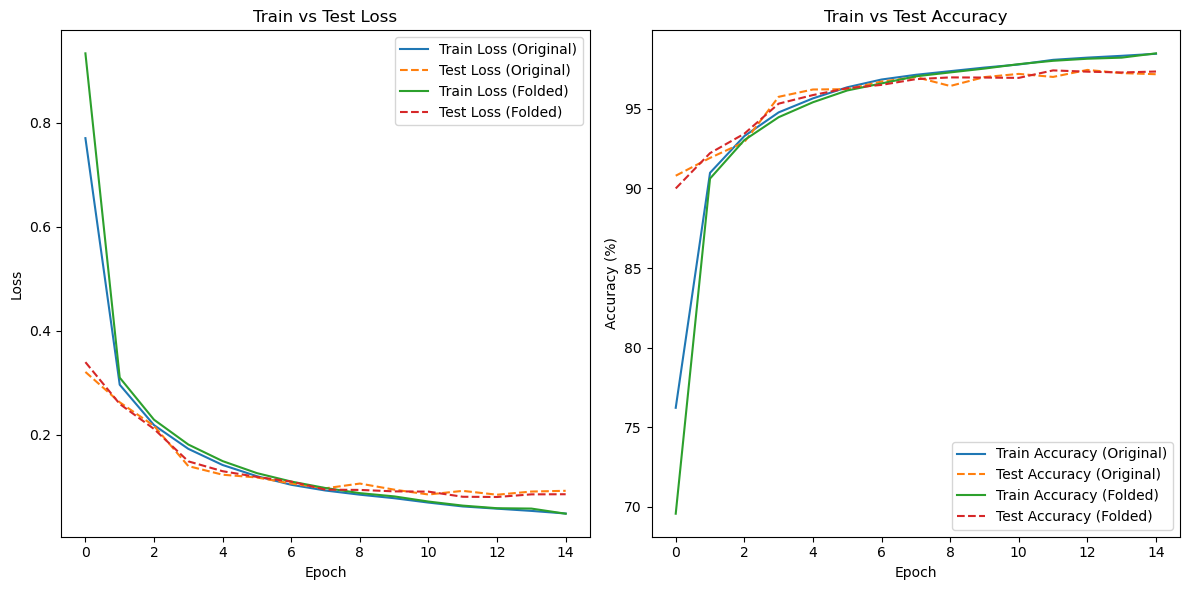

In [64]:
# 訓練とテストの損失をプロット
plt.figure(figsize=(12, 6))

# 損失のプロット
plt.subplot(1, 2, 1)
plt.plot(range(epochs), orig_train_losses,   label='Train Loss (Original)')
plt.plot(range(epochs), orig_test_losses,    label='Test Loss (Original)', linestyle='--')
plt.plot(range(epochs), folded_train_losses, label='Train Loss (Folded)')
plt.plot(range(epochs), folded_test_losses,  label='Test Loss (Folded)', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train vs Test Loss')
plt.legend()

# 精度のプロット
plt.subplot(1, 2, 2)
plt.plot(range(epochs), orig_train_accuracies, label='Train Accuracy (Original)')
plt.plot(range(epochs), orig_test_accuracies, label='Test Accuracy (Original)', linestyle='--')
plt.plot(range(epochs), folded_train_accuracies, label='Train Accuracy (Folded)')
plt.plot(range(epochs), folded_test_accuracies, label='Test Accuracy (Folded)', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Train vs Test Accuracy')
plt.legend()

# プロットを表示
plt.tight_layout()
plt.show()

## 5. テーマの割り当て

- テーマA：重みとアクティベーションの量子化感度評価と効率的量子化パラメータ設定
- テーマB：ニューラルネットワーク重みにおけるベクトル量子化とスカラー量子化の効率度比較とその融合手法の検討
- テーマC：量子化と多層分解を同時に行う場合の、深さとビット幅の最適比
- テーマD：量子化と枝刈りを同時に行う場合の、ビット幅とスパーシティの最適比
- テーマE：Looped LLMにおける重み量子化ビット幅と、精度・モデルサイズのトレードオフ
- テーマF：Looped LLMの再帰回数と、精度・収束性・計算量の関係